# Ejemplo 1 — Sección rectangular de hormigón sin armadura

Cálculo de la **deformación** y la **tensión** de una sección rectangular de
hormigón sin refuerzo con el **solver completo de la librería**:

`ComponenteSeccion` → `Seccion` → `Fase` → `ModeloEstructural`
→ `analizar_fases` → `HistorialSeccion` → muestreo con `preparar_componentes`.

No se construyen a mano `ComponenteCalculo` ni `EstadoSeccionFase`: los genera
la propia orquestación `analizar_fases`.

## Casos del ejemplo

| Caso | Esfuerzo |
|---|---|
| **1.1** | $M_y = +100\ \mathrm{kN\,m}$ |
| **1.2** | $M_z = +50\ \mathrm{kN\,m}$ |
| **1.3** | $N = -300\ \mathrm{kN}$ (compresión) $+\ M_y = +25\ \mathrm{kN\,m}$ |

## Hipótesis y convenio

- Sección rectangular de $b = 400\ \text{mm}$ (eje $y$) y
  $h = 500\ \text{mm}$ (eje $z$), centrada en el origen.
- Hormigón **HA-60** del Código Estructural.
- Ley constitutiva **elástica lineal** inyectada por
  `ProveedorLeyesElasticas`.
- Hipótesis de Bernoulli:
  $\varepsilon(y,z) = \varepsilon_0 + \kappa_y z - \kappa_z y$.
- Deformaciones positivas a tracción; tensiones positivas a tracción.
- $M_y > 0$ tracciona la fibra inferior ($z < 0$); $M_z > 0$ tracciona la
  fibra derecha ($y > 0$).
- $N > 0$ es tracción; por tanto, $300\ \text{kN}$ de compresión se
  introducen como $N = -300\,000\ \text{N}$.
- Unidades: mm, N, MPa, N·mm.

> **Alcance:** cálculo elástico instantáneo. No se resuelve la fisuración ni se
> cambia la ley constitutiva.

In [1]:
from __future__ import annotations

import math
import sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from placas_alveolares.domain.mechanics.analisis_fases import analizar_fases
from placas_alveolares.domain.mechanics.generic_laws import LeyElastica
from placas_alveolares.domain.mechanics.laws import LeyTensionDeformacion
from placas_alveolares.domain.mechanics.preparacion_componentes import (
    ComponenteCalculo,
    preparar_componentes,
)
from placas_alveolares.domain.mechanics.propiedades_seccion import (
    propiedades_geometricas,
)
from placas_alveolares.domain.mechanics.proveedor_leyes_elasticas import (
    ProveedorLeyesElasticas,
)
from placas_alveolares.domain.model.acciones import EsfuerzosInternos
from placas_alveolares.domain.model.fases import Fase
from placas_alveolares.domain.model.geometria import rectangulo
from placas_alveolares.domain.model.modelo import ModeloEstructural
from placas_alveolares.domain.model.seccion import ComponenteSeccion, Seccion
from placas_alveolares.domain.model.tiempo import Tiempo
from placas_alveolares.domain.numerics import Newton, OpcionesNewton
from placas_alveolares.domain.state.estado_seccion import EstadoSeccionFase
from placas_alveolares.domain.state.historial_seccion import HistorialSeccion
from placas_alveolares.norms.ce.materiales.hormigones import hormigon

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
    }
)

## 1. Definición de la sección

La sección se declara con los tipos del modelo estructural:

- `ComponenteSeccion`: geometría rectangular y material HA-60.
- `Seccion`: agrupación de componentes.

Las propiedades geométricas de referencia se obtienen con el motor
`propiedades_geometricas`, no con fórmulas locales.

In [2]:
ANCHO = 400.0
ALTO = 500.0
MATERIAL = hormigon("HA-60")

COMPONENTE = ComponenteSeccion(
    id="hormigon",
    geometria=rectangulo(ANCHO, ALTO, z_base=-ALTO / 2.0),
    material=MATERIAL,
)
SECCION = Seccion(componentes=(COMPONENTE,))

PROPIEDADES = propiedades_geometricas(COMPONENTE.geometria)
AREA = PROPIEDADES.area
INERCIA_Y = PROPIEDADES.i_y
INERCIA_Z = PROPIEDADES.i_z
MODULO_Y = INERCIA_Y / (ALTO / 2.0)
MODULO_Z = INERCIA_Z / (ANCHO / 2.0)

print("Hormigón HA-60 (Código Estructural)")
print(f"  fck  = {MATERIAL.fck:.1f} MPa")
print(f"  fcm  = {MATERIAL.fcm:.1f} MPa")
print(f"  Ecm  = {MATERIAL.ecm:,.0f} MPa".replace(",", "."))
print()
print(f"  b = {ANCHO:.0f} mm, h = {ALTO:.0f} mm")
print(f"  A   = {AREA:,.0f} mm²".replace(",", "."))
print(f"  Iy  = {INERCIA_Y:,.0f} mm⁴".replace(",", "."))
print(f"  Iz  = {INERCIA_Z:,.0f} mm⁴".replace(",", "."))
print(f"  Wy  = {MODULO_Y:,.0f} mm³".replace(",", "."))
print(f"  Wz  = {MODULO_Z:,.0f} mm³".replace(",", "."))
print(f"  y_cdg = {PROPIEDADES.y_cdg:.3e} mm")
print(f"  z_cdg = {PROPIEDADES.z_cdg:.3e} mm")

Hormigón HA-60 (Código Estructural)
  fck  = 60.0 MPa
  fcm  = 68.0 MPa
  Ecm  = 39.100 MPa

  b = 400 mm, h = 500 mm
  A   = 200.000 mm²
  Iy  = 4.166.666.667 mm⁴
  Iz  = 2.666.666.667 mm⁴
  Wy  = 16.666.667 mm³
  Wz  = 13.333.333 mm³
  y_cdg = 0.000e+00 mm
  z_cdg = 2.328e-15 mm


## 2. Proveedor de leyes y solver

`ProveedorLeyesElasticas` es el proveedor de la librería que convierte cada
componente en una `LeyElastica` con el módulo de su material. El solver no
lineal se inyecta como `Newton`.

In [3]:
PROVEEDOR_LEYES = ProveedorLeyesElasticas()
SOLVER = Newton(
    OpcionesNewton(
        tolerancia_residuo=1.0e-10,
        tolerancia_residuo_relativa=1.0e-10,
        max_iteraciones=100,
    )
)

## 3. Casos de carga y resolución

Cada caso se representa con una `Fase` instantánea que contiene sus
`EsfuerzosInternos`. La fase se integra en un `ModeloEstructural`, y
`analizar_fases` se encarga de:

1. activar los componentes,
2. preparar mallas y leyes,
3. resolver el equilibrio,
4. devolver el `HistorialSeccion`.

El estado resultante se obtiene con `historial.estado(0)`. Para muestrear
tensiones se vuelven a preparar los componentes con la misma fase: así se
reutilizan la geometría efectiva, la malla y la ley que ha inyectado el
proveedor.

In [4]:
@dataclass(frozen=True, slots=True)
class DefinicionCaso:
    """Datos de entrada de un caso de carga."""

    caso: str
    descripcion: str
    acciones: EsfuerzosInternos


@dataclass(frozen=True, slots=True)
class PuntoResultado:
    """Tensión y deformación en una esquina de la sección."""

    nombre: str
    y: float
    z: float
    deformacion: float
    tension: float


@dataclass(frozen=True, slots=True)
class ResultadoCaso:
    """Resultado completo de un caso resuelto por la librería."""

    definicion: DefinicionCaso
    fase: Fase
    modelo: ModeloEstructural
    historial: HistorialSeccion
    estado: EstadoSeccionFase
    componente: ComponenteCalculo
    puntos: tuple[PuntoResultado, ...]
    eje_variacion: str
    coordenada_neutra: float
    tension_maxima_traccion: float


_ESQUINAS = (
    ("superior izquierda", -ANCHO / 2.0, ALTO / 2.0),
    ("superior derecha", ANCHO / 2.0, ALTO / 2.0),
    ("inferior izquierda", -ANCHO / 2.0, -ALTO / 2.0),
    ("inferior derecha", ANCHO / 2.0, -ALTO / 2.0),
)


def _punto_resultado(
    componente: ComponenteCalculo,
    estado: EstadoSeccionFase,
    nombre: str,
    y: float,
    z: float,
) -> PuntoResultado:
    """Muestrea deformación y tensión en un punto de la sección."""
    estado_componente = estado.componente_requerido(
        componente.componente_id
    )
    constitutiva = estado_componente.deformacion_constitutiva(
        estado.plano_comun
    )
    deformacion = constitutiva.deformacion(y, z)
    return PuntoResultado(
        nombre=nombre,
        y=y,
        z=z,
        deformacion=deformacion,
        tension=componente.ley.tension(deformacion),
    )


def resolver_caso(definicion: DefinicionCaso) -> ResultadoCaso:
    """Resuelve un caso con el pipeline completo de la librería."""
    fase = Fase(
        indice=0,
        tiempo_inicio=Tiempo(0.0),
        tiempo_fin=Tiempo(0.0),
        acciones=definicion.acciones,
        nombre=f"Caso {definicion.caso}",
    )
    modelo = ModeloEstructural(
        seccion=SECCION,
        fases=(fase,),
        fase_activa=0,
    )
    historial = analizar_fases(modelo, PROVEEDOR_LEYES, SOLVER)
    estado = historial.estado(0)
    if estado.equilibrio is None:
        raise RuntimeError("La fase no resolvió el equilibrio.")

    componentes = preparar_componentes(
        modelo.seccion,
        fase,
        estado,
        PROVEEDOR_LEYES,
    )
    if len(componentes) != 1:
        raise RuntimeError("Se esperaba un único componente de hormigón.")
    componente = componentes[0]

    puntos = tuple(
        _punto_resultado(componente, estado, nombre, y, z)
        for nombre, y, z in _ESQUINAS
    )
    tension_maxima_traccion = max(
        0.0, max(punto.tension for punto in puntos)
    )

    plano = estado.plano_comun
    if abs(plano.kappa_y) >= abs(plano.kappa_z):
        eje_variacion = "z"
        coordenada_neutra = (
            -plano.eps0 / plano.kappa_y
            if plano.kappa_y != 0.0
            else math.nan
        )
    else:
        eje_variacion = "y"
        coordenada_neutra = (
            plano.eps0 / plano.kappa_z
            if plano.kappa_z != 0.0
            else math.nan
        )
    if math.isfinite(coordenada_neutra) and abs(coordenada_neutra) < 1.0e-9:
        coordenada_neutra = 0.0

    return ResultadoCaso(
        definicion=definicion,
        fase=fase,
        modelo=modelo,
        historial=historial,
        estado=estado,
        componente=componente,
        puntos=puntos,
        eje_variacion=eje_variacion,
        coordenada_neutra=coordenada_neutra,
        tension_maxima_traccion=tension_maxima_traccion,
    )

## 4. Resultados de los casos 1.1, 1.2 y 1.3

En cada caso se muestra el plano resuelto, el resumen de equilibrio que
devuelve `analizar_fases`, el tipo de ley preparada y las deformaciones y
tensiones en las cuatro esquinas.

In [5]:
CASOS = (
    resolver_caso(
        DefinicionCaso(
            "1.1",
            "My = +100 kN·m",
            EsfuerzosInternos(m_y=100.0e6),
        )
    ),
    resolver_caso(
        DefinicionCaso(
            "1.2",
            "Mz = +50 kN·m",
            EsfuerzosInternos(m_z=50.0e6),
        )
    ),
    resolver_caso(
        DefinicionCaso(
            "1.3",
            "N = -300 kN + My = +25 kN·m",
            EsfuerzosInternos(n=-300.0e3, m_y=25.0e6),
        )
    ),
)

for resultado in CASOS:
    equilibrio = resultado.estado.equilibrio
    if equilibrio is None:
        raise RuntimeError("Falta el resumen de equilibrio.")
    print(f"Caso {resultado.definicion.caso} — {resultado.definicion.descripcion}")
    print(f"  eps0 = {resultado.estado.plano_comun.eps0: .6e}")
    print(f"  ky   = {resultado.estado.plano_comun.kappa_y: .6e} 1/mm")
    print(f"  kz   = {resultado.estado.plano_comun.kappa_z: .6e} 1/mm")
    print(
        f"  Eje de variación: {resultado.eje_variacion}; "
        f"fibra neutra: {resultado.coordenada_neutra:.1f} mm"
    )
    print(f"  Ley preparada: {type(resultado.componente.ley).__name__}")
    print(
        f"  Equilibrio: N = {equilibrio.resultantes.n:.3f} N; "
        f"My = {equilibrio.resultantes.m_y / 1e6:.4f} kN·m; "
        f"Mz = {equilibrio.resultantes.m_z / 1e6:.4f} kN·m"
    )
    print(
        f"  {'Esquina':<20}{'y (mm)':>9}{'z (mm)':>9}"
        f"{'eps (‰)':>13}{'sigma (MPa)':>14}"
    )
    for punto in resultado.puntos:
        deformacion_mostrada = (
            0.0 if abs(punto.deformacion) < 1.0e-12 else punto.deformacion
        )
        tension_mostrada = (
            0.0 if abs(punto.tension) < 1.0e-12 else punto.tension
        )
        print(
            f"  {punto.nombre:<20}{punto.y:>9.1f}{punto.z:>9.1f}"
            f"{deformacion_mostrada * 1000.0:>13.4f}"
            f"{tension_mostrada:>14.4f}"
        )
    print(
        f"  Iteraciones: {equilibrio.iteraciones}; "
        f"residuo = {equilibrio.norma_residuo:.3e}"
    )
    print()

print(
    f"{'Caso':<6}{'My (kN·m)':>12}{'Mz (kN·m)':>12}{'N (kN)':>10}"
    f"{'ky (1/mm)':>14}{'kz (1/mm)':>14}"
    f"{'sigma_max,t':>14}"
)
for resultado in CASOS:
    print(
        f"{resultado.definicion.caso:<6}"
        f"{resultado.definicion.acciones.m_y / 1e6:>12.2f}"
        f"{resultado.definicion.acciones.m_z / 1e6:>12.2f}"
        f"{resultado.definicion.acciones.n / 1e3:>10.2f}"
        f"{resultado.estado.plano_comun.kappa_y:>14.3e}"
        f"{resultado.estado.plano_comun.kappa_z:>14.3e}"
        f"{resultado.tension_maxima_traccion:>14.3f}"
    )

Caso 1.1 — My = +100 kN·m
  eps0 =  4.568890e-21
  ky   = -6.138127e-07 1/mm
  kz   = -2.193067e-23 1/mm
  Eje de variación: z; fibra neutra: 0.0 mm
  Ley preparada: LeyElastica
  Equilibrio: N = 0.000 N; My = 100.0000 kN·m; Mz = 0.0000 kN·m
  Esquina                y (mm)   z (mm)      eps (‰)   sigma (MPa)
  superior izquierda     -200.0    250.0      -0.1535       -6.0000
  superior derecha        200.0    250.0      -0.1535       -6.0000
  inferior izquierda     -200.0   -250.0       0.1535        6.0000
  inferior derecha        200.0   -250.0       0.1535        6.0000
  Iteraciones: 2; residuo = 0.000e+00

Caso 1.2 — Mz = +50 kN·m
  eps0 =  1.469686e-21
  ky   = -2.574838e-25 1/mm
  kz   = -4.795412e-07 1/mm
  Eje de variación: y; fibra neutra: 0.0 mm
  Ley preparada: LeyElastica
  Equilibrio: N = 0.000 N; My = -0.0000 kN·m; Mz = 50.0000 kN·m
  Esquina                y (mm)   z (mm)      eps (‰)   sigma (MPa)
  superior izquierda     -200.0    250.0      -0.0959       -3.7500
  

## 5. Comparación con la solución analítica

Para una sección homogénea no fisurada con ejes principales:

$$
\kappa_y = -\frac{M_y}{E_{cm} I_y}, \qquad
\kappa_z = -\frac{M_z}{E_{cm} I_z}, \qquad
\varepsilon_0 = \frac{N}{E_{cm} A}
$$

y la tensión normal es:

$$
\sigma(y,z) = \frac{N}{A} - \frac{M_y z}{I_y} + \frac{M_z y}{I_z}
$$

Las propiedades $A$, $I_y$ e $I_z$ se han obtenido con
`propiedades_geometricas`. La comparación valida el equilibrio, la integración
y la convención de signos.

In [6]:
def plano_analitico(acciones: EsfuerzosInternos) -> tuple[float, float, float]:
    """Plano de deformaciones de la solución elástica cerrada."""
    eps0 = acciones.n / (MATERIAL.ecm * AREA)
    kappa_y = -acciones.m_y / (MATERIAL.ecm * INERCIA_Y)
    kappa_z = -acciones.m_z / (MATERIAL.ecm * INERCIA_Z)
    return eps0, kappa_y, kappa_z


def tension_analitica(y: float, z: float, acciones: EsfuerzosInternos) -> float:
    """Tensión normal de la solución elástica cerrada."""
    return (
        acciones.n / AREA
        - acciones.m_y * z / INERCIA_Y
        + acciones.m_z * y / INERCIA_Z
    )


print(
    f"{'Caso':<6}{'error eps0':>14}{'error ky':>14}"
    f"{'error kz':>14}{'error sigma max':>18}"
)
for resultado in CASOS:
    eps0, kappa_y, kappa_z = plano_analitico(resultado.definicion.acciones)
    error_eps0 = abs(resultado.estado.plano_comun.eps0 - eps0)
    error_ky = abs(resultado.estado.plano_comun.kappa_y - kappa_y)
    error_kz = abs(resultado.estado.plano_comun.kappa_z - kappa_z)
    error_sigma = max(
        abs(
            punto.tension
            - tension_analitica(
                punto.y,
                punto.z,
                resultado.definicion.acciones,
            )
        )
        for punto in resultado.puntos
    )
    print(
        f"{resultado.definicion.caso:<6}{error_eps0:>14.3e}"
        f"{error_ky:>14.3e}{error_kz:>14.3e}{error_sigma:>18.3e}"
    )

Caso      error eps0      error ky      error kz   error sigma max
1.1        4.569e-21     1.059e-22     2.193e-23         0.000e+00
1.2        1.470e-21     2.575e-25     0.000e+00         4.441e-16
1.3        1.325e-15     5.301e-18     5.483e-24         1.036e-10


### Comprobaciones tipo test

Estas aserciones son el puente hacia el test de pytest. Comprueban que el
pipeline completo devuelve el plano y las resultantes esperadas, que el
proveedor inyecta una `LeyElastica`, que el historial contiene la fase y que
las tensiones muestreadas coinciden con la solución analítica.

In [7]:
for resultado in CASOS:
    acciones = resultado.definicion.acciones
    eps0, kappa_y, kappa_z = plano_analitico(acciones)

    assert resultado.historial.estado(0) == resultado.estado
    assert resultado.componente.componente_id == "hormigon"
    assert len(resultado.componente.malla) > 0
    assert isinstance(resultado.componente.ley, LeyElastica)

    np.testing.assert_allclose(
        resultado.estado.plano_comun.eps0,
        eps0,
        rtol=0.0,
        atol=1.0e-12,
    )
    np.testing.assert_allclose(
        resultado.estado.plano_comun.kappa_y,
        kappa_y,
        rtol=0.0,
        atol=1.0e-15,
    )
    np.testing.assert_allclose(
        resultado.estado.plano_comun.kappa_z,
        kappa_z,
        rtol=0.0,
        atol=1.0e-15,
    )

    equilibrio = resultado.estado.equilibrio
    assert equilibrio is not None
    np.testing.assert_allclose(
        equilibrio.resultantes.n,
        acciones.n,
        rtol=1.0e-9,
        atol=0.1,
    )
    np.testing.assert_allclose(
        equilibrio.resultantes.m_y,
        acciones.m_y,
        rtol=1.0e-9,
        atol=0.1,
    )
    np.testing.assert_allclose(
        equilibrio.resultantes.m_z,
        acciones.m_z,
        rtol=1.0e-9,
        atol=0.1,
    )

    for punto in resultado.puntos:
        np.testing.assert_allclose(
            punto.tension,
            tension_analitica(punto.y, punto.z, acciones),
            rtol=1.0e-9,
            atol=1.0e-9,
        )

np.testing.assert_allclose(
    CASOS[2].coordenada_neutra,
    -ALTO / 2.0,
    rtol=0.0,
    atol=1.0e-6,
)
print("Comprobaciones tipo test superadas.")

Comprobaciones tipo test superadas.


## 6. Diagramas de deformación y tensión

Cada fila corresponde a un caso. La primera columna es el mapa de tensiones
$\sigma(y,z)$; la segunda, la deformación a lo largo de la fibra variable; la
tercera, la tensión en esa misma fibra. La línea vertical de los diagramas
marca el valor nulo y la línea horizontal punteada, cuando queda dentro de la
sección, la fibra neutra.

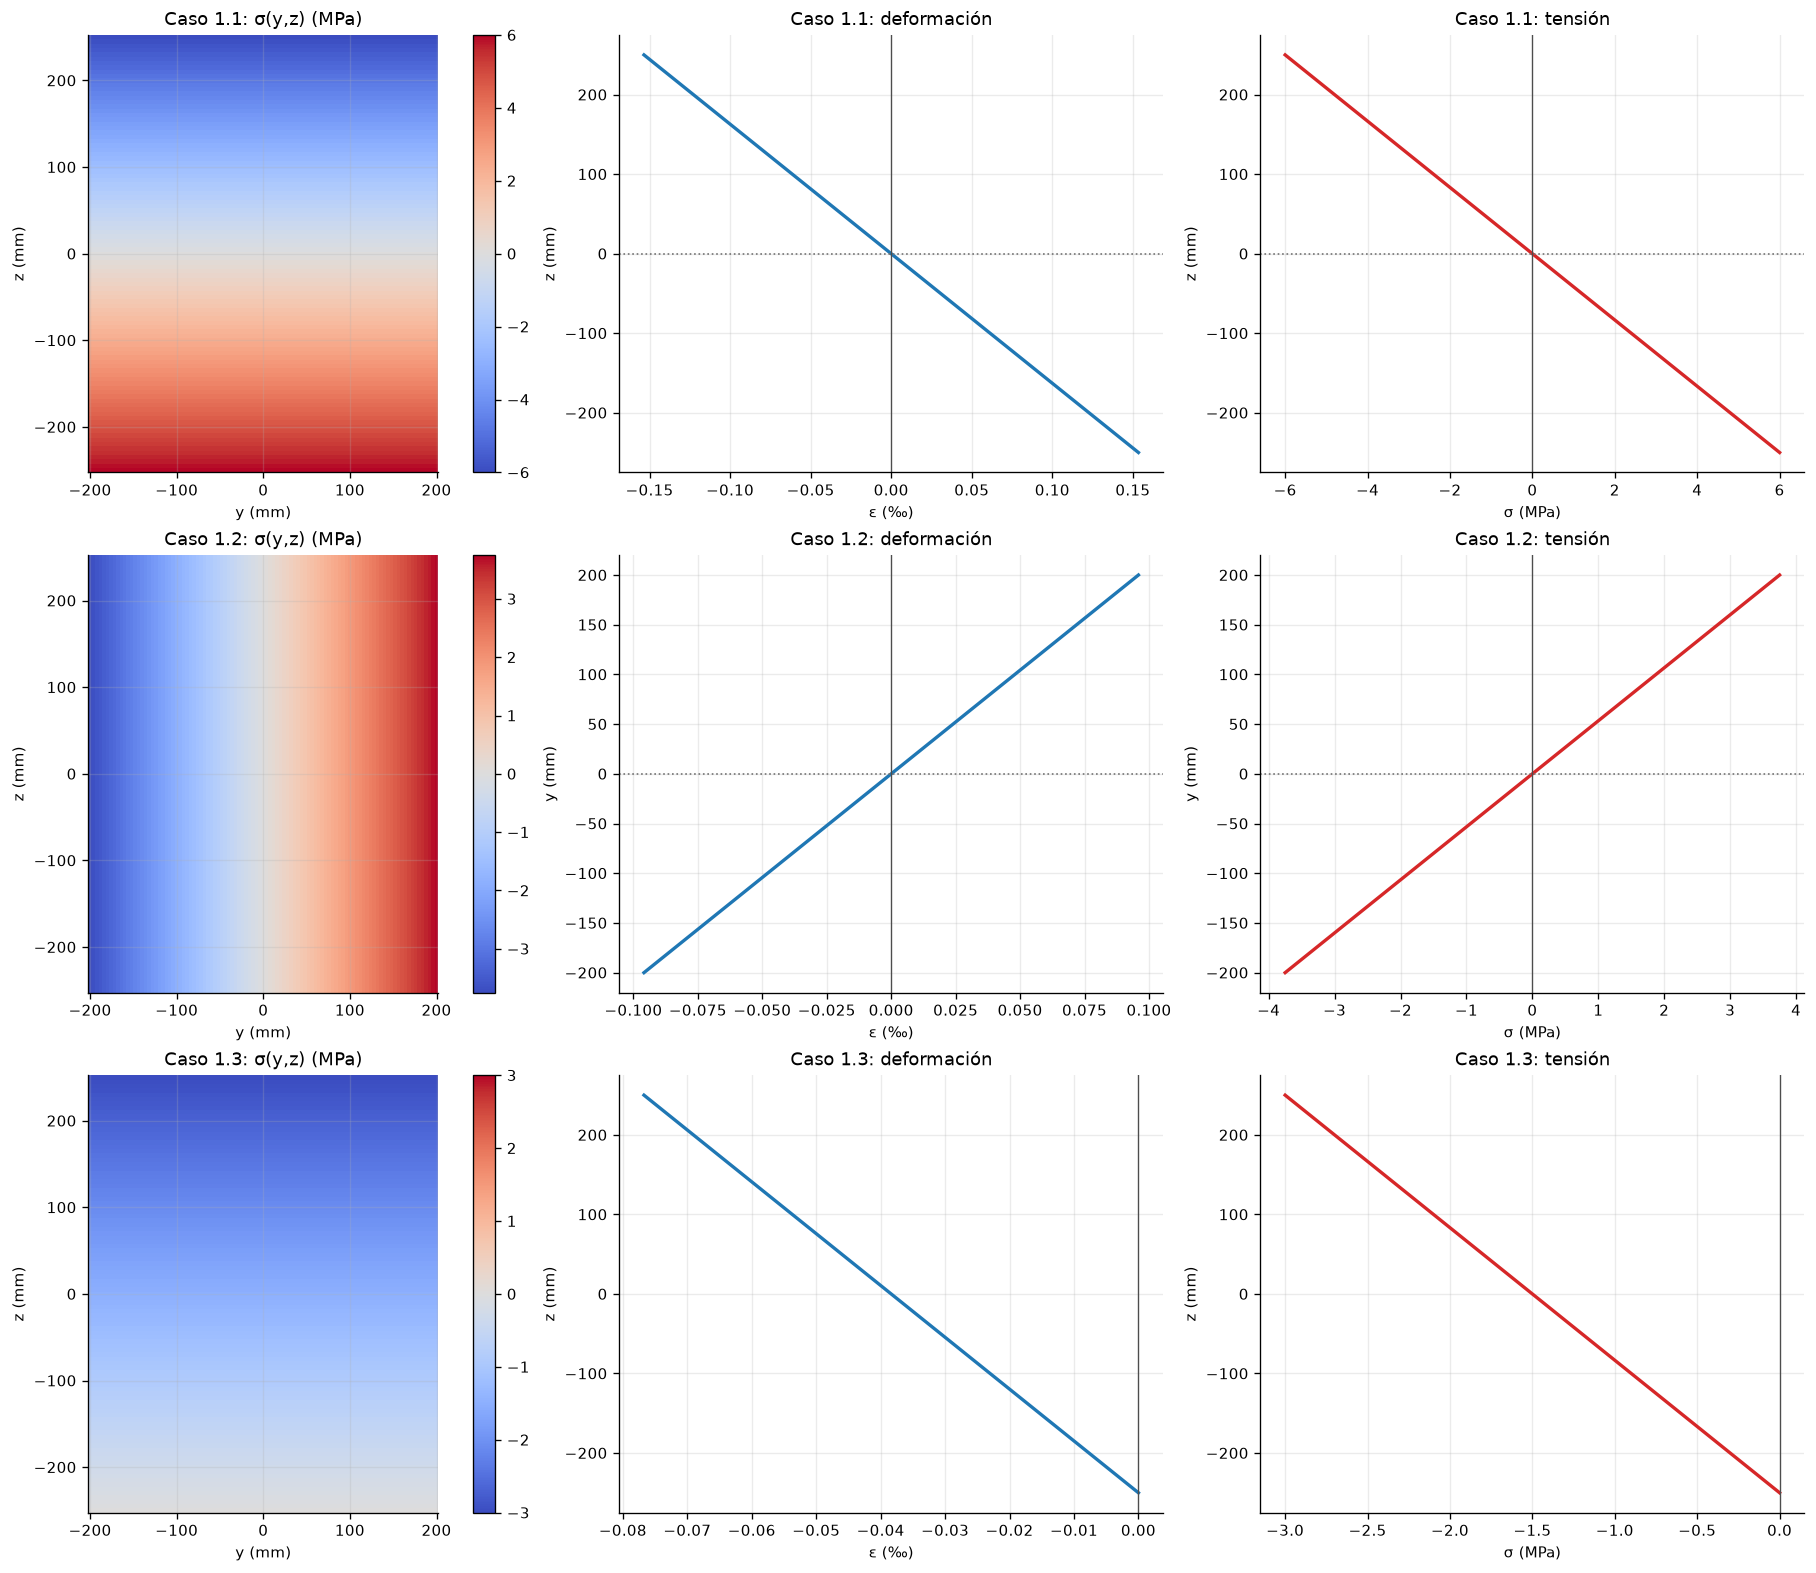

In [8]:
def _valores_ley(
    ley: LeyTensionDeformacion,
    deformaciones: np.ndarray,
) -> np.ndarray:
    """Evalúa una ley constitutiva sobre un array de deformaciones."""
    return np.array([ley.tension(float(e)) for e in deformaciones])


def dibujar_caso(
    resultado: ResultadoCaso,
    ax_mapa: plt.Axes,
    ax_eps: plt.Axes,
    ax_sigma: plt.Axes,
) -> None:
    """Dibuja el mapa de tensiones y los diagramas de la fibra variable."""
    plano = resultado.estado.plano_comun
    ley = resultado.componente.ley
    y = np.linspace(-ANCHO / 2.0, ANCHO / 2.0, 101)
    z = np.linspace(-ALTO / 2.0, ALTO / 2.0, 101)
    malla_y, malla_z = np.meshgrid(y, z)
    deformaciones = (
        plano.eps0 + plano.kappa_y * malla_z - plano.kappa_z * malla_y
    )
    tensiones = _valores_ley(ley, deformaciones.ravel()).reshape(
        deformaciones.shape
    )
    limite = max(
        abs(float(tensiones.min())), abs(float(tensiones.max())), 1.0e-9
    )
    mapa = ax_mapa.pcolormesh(
        malla_y,
        malla_z,
        tensiones,
        shading="auto",
        cmap="coolwarm",
        vmin=-limite,
        vmax=limite,
    )
    ax_mapa.set_aspect("equal")
    ax_mapa.set_xlabel("y (mm)")
    ax_mapa.set_ylabel("z (mm)")
    ax_mapa.set_title(f"Caso {resultado.definicion.caso}: σ(y,z) (MPa)")
    plt.colorbar(mapa, ax=ax_mapa, fraction=0.046, pad=0.04)

    if resultado.eje_variacion == "z":
        coordenada = np.linspace(-ALTO / 2.0, ALTO / 2.0, 401)
        deformaciones_fibra = plano.eps0 + plano.kappa_y * coordenada
        etiqueta_coordenada = "z (mm)"
    else:
        coordenada = np.linspace(-ANCHO / 2.0, ANCHO / 2.0, 401)
        deformaciones_fibra = plano.eps0 - plano.kappa_z * coordenada
        etiqueta_coordenada = "y (mm)"
    tensiones_fibra = _valores_ley(ley, deformaciones_fibra)

    ax_eps.plot(
        deformaciones_fibra * 1000.0,
        coordenada,
        color="tab:blue",
        linewidth=2.0,
    )
    ax_eps.axvline(0.0, color="0.3", linewidth=0.8)
    ax_eps.set_xlabel("ε (‰)")
    ax_eps.set_ylabel(etiqueta_coordenada)
    ax_eps.set_title(f"Caso {resultado.definicion.caso}: deformación")

    ax_sigma.plot(
        tensiones_fibra,
        coordenada,
        color="tab:red",
        linewidth=2.0,
    )
    ax_sigma.axvline(0.0, color="0.3", linewidth=0.8)
    ax_sigma.set_xlabel("σ (MPa)")
    ax_sigma.set_ylabel(etiqueta_coordenada)
    ax_sigma.set_title(f"Caso {resultado.definicion.caso}: tensión")

    if math.isfinite(resultado.coordenada_neutra):
        if (
            resultado.eje_variacion == "z"
            and -ALTO / 2.0 < resultado.coordenada_neutra < ALTO / 2.0
        ):
            for eje in (ax_eps, ax_sigma):
                eje.axhline(
                    resultado.coordenada_neutra,
                    color="0.45",
                    linestyle=":",
                    linewidth=1.0,
                )
        if (
            resultado.eje_variacion == "y"
            and -ANCHO / 2.0 < resultado.coordenada_neutra < ANCHO / 2.0
        ):
            for eje in (ax_eps, ax_sigma):
                eje.axhline(
                    resultado.coordenada_neutra,
                    color="0.45",
                    linestyle=":",
                    linewidth=1.0,
                )


fig, ejes = plt.subplots(3, 3, figsize=(16, 13), constrained_layout=True)
for resultado, fila in zip(CASOS, ejes):
    dibujar_caso(resultado, fila[0], fila[1], fila[2])
plt.show()

## 7. Para consolidar como test

El cuaderno usa el mismo camino que debería usar el test:

`ComponenteSeccion` → `Seccion` → `Fase` → `ModeloEstructural` →
`analizar_fases` → `HistorialSeccion` → `preparar_componentes` → muestreo.

Nombres naturales de los tests:

- `test_ejemplo_1_1_flexion_my`
- `test_ejemplo_1_2_flexion_mz`
- `test_ejemplo_1_3_compresion_con_flexion`
- `test_ejemplo_1_pipeline_completo`

Invariantes:

- $\kappa_y \approx -M_y/(E_{cm} I_y)$ y
  $\kappa_z \approx -M_z/(E_{cm} I_z)$.
- $\varepsilon_0 \approx N/(E_{cm} A)$.
- $\sigma(y,z) \approx N/A - M_y z/I_y + M_z y/I_z$ en las cuatro esquinas.
- $N_{int} \approx N_{aplicado}$ y $M_{int} \approx M_{aplicado}$.
- El historial contiene la fase 0 y el estado se obtiene con `estado(0)`.
- La ley preparada es `LeyElastica`.
- Fibra neutra en $z = -250\ \text{mm}$ para el caso 1.3.

Ubicación propuesta: `tests/unit/domain/test_solver_deformaciones.py` o un
nuevo `tests/unit/domain/test_ejemplo_1_hormigon_sin_armadura.py`.

## Cómo ejecutar el cuaderno

```powershell
.venv\Scripts\activate
pip install -e ".[notebooks]"
jupyter nbconvert --execute --to notebook --inplace notebooks/ejemplo_1_hormigon_sin_armadura.ipynb
```

El cuaderno está pensado para **leerse en GitHub** con las gráficas ya
embebidas. Si se editan los parámetros (`ANCHO`, `ALTO` o los casos), basta
con volver a ejecutarlo para actualizar las salidas.